# Couette (concentric-cylinder) rheometry of a Herschel–Bulkley fluid

A rotational rheometer does not measure a flow curve. It measures a **torque** and an **angular velocity**, and the shear stress and shear rate are inferred from them through a model of the instrument. For a Newtonian liquid in a narrow gap that model is trivial. For a yield-stress fluid it is not: the shear stress in a concentric-cylinder (Couette) cell falls off as $1/r^2$ across the gap, so the material near the outer cylinder can stay solid while the material near the bob flows. If such data are converted to stress and shear rate with the usual Newtonian formulas, the "measured" flow curve — and hence the fitted yield stress, consistency and flow index — is biased. This notebook works through the exact torque–speed relation for a Herschel–Bulkley (HB) fluid, shows when the gap is fully sheared, quantifies the bias of the Newtonian conversion, and reproduces Fig. 6 of the review.

## Where this is in the review

* **Sec. VI B** *Inverting the instrument response* — the partially sheared gap, the condition $\sigma_b \ge \sigma_y (R_o/R_i)^2$, and the bias of the Newtonian conversion (Fig. 6).
* **Sec. VII A** *Steady flow in pipes, channels and Couette cells* — stress distribution $\sigma(r)=T/(2\pi r^2)$, yielded radius $r_y$, and the exact torque–speed relation **Eq. (21)**.
* **Fig. 6** — (a) sheared fraction of the gap versus bob stress; (b) apparent flow curves from the Newtonian conversion. Script `scripts/fig06_couette_inverse.py`; fitted coefficients in `data/couette_illustration.json`; plotted values in `data/figure_data/fig06_couette_inverse.csv`.
* **Eq. (3)** — the HB law $\sigma=\sigma_y+K\dot\gamma^n$ in simple shear.
* **Supplementary Note S7 A** — Eq. (S15) (Eq. (21) written as an integral over stress), Eq. (S16) (near-onset asymptote) and Table SIV (near-onset exponents).
* **Supplementary Note S11 A**, Table SV — Eq. (21) is checked against the Newtonian, power-law and Bingham closed forms (`scripts/verify_equations.py`).
* **Sec. VI C** — wall slip and confinement, which limit how narrow a gap can usefully be.

## Learning objectives

After working through this notebook you should be able to

1. derive the stress distribution $\sigma(r)$ in a Couette cell and locate the yielded radius $r_y$;
2. state when the gap is partially sheared and when it is fully sheared;
3. evaluate the exact torque–angular-velocity relation, Eq. (21), and check it against its Newtonian, power-law and Bingham limits;
4. explain, and quantify, why converting partially sheared data with Newtonian factors biases the flow curve and the fitted HB parameters;
5. choose a gap ratio and an analysis route (narrow gap, or a forward-model fit of the raw torque and speed) for a yield-stress fluid.

## 1. Theory

### 1.1 Stress distribution across the gap

Consider an inner cylinder (the *bob*) of radius $R_i$ rotating at angular velocity $\Omega$ inside a stationary outer cylinder (the *cup*) of radius $R_o$. Write $\kappa = R_o/R_i$ for the radius ratio. Neglect end effects and inertia, and assume no slip. In steady azimuthal flow the torque transmitted through every cylindrical surface $r$ is the same, so with $T$ the torque per unit immersed length,

$$
2\pi r^2\,\sigma(r) = T
\qquad\Longrightarrow\qquad
\sigma(r) = \frac{T}{2\pi r^2} = \sigma_b\left(\frac{R_i}{r}\right)^2 ,
\qquad \sigma_b \equiv \frac{T}{2\pi R_i^2},
$$

where $\sigma_b$ is the shear stress at the bob. The stress at the cup is $\sigma_o=\sigma_b/\kappa^2$. Unlike pipe flow, where the stress grows linearly with radius, here the stress is **largest at the inner wall** and decays as $r^{-2}$.

### 1.2 Yielded radius and the three regimes

The HB material flows only where $\sigma>\sigma_y$. Setting $\sigma(r_y)=\sigma_y$ gives the yielded radius

$$
r_y = \sqrt{\frac{T}{2\pi\sigma_y}} = R_i\sqrt{\frac{\sigma_b}{\sigma_y}} .
$$

* $\sigma_b\le\sigma_y$ (i.e. $T\le 2\pi R_i^2\sigma_y$): nothing flows and $\Omega=0$.
* $\sigma_y<\sigma_b<\sigma_y\kappa^2$: **partially sheared gap.** Only the layer $R_i<r<r_y$ is sheared; the material between $r_y$ and $R_o$ is unyielded and stays at rest with the cup (Reiner and Riwlin, 1927).
* $\sigma_b\ge\sigma_y\kappa^2$: **fully sheared gap.** This is the condition $\sigma_b \ge \sigma_y (R_o/R_i)^2$ quoted in Secs. VI B and VII A.

The sheared fraction of the gap plotted in Fig. 6(a) is $\min\{(r_y-R_i)/(R_o-R_i),\,1\}$.

### 1.3 Torque–speed relation, Eq. (21)

With $u_\theta=r\,\omega(r)$ the shear-rate magnitude is $\dot\gamma=-r\,\mathrm{d}\omega/\mathrm{d}r$ (the angular velocity decreases outwards). Integrating $\mathrm{d}\omega = -\dot\gamma\,\mathrm{d}r/r$ from the bob to the edge of the sheared layer, where $\omega=0$, and inserting the inverse of the HB law, $\dot\gamma=[(\sigma-\sigma_y)/K]^{1/n}$, gives Eq. (21) of the review:

$$
\Omega = \int_{R_i}^{\min(r_y,R_o)} \frac{1}{r}\left(\frac{\sigma(r)-\sigma_y}{K}\right)^{1/n}\mathrm{d}r ,
\qquad T>2\pi R_i^2\sigma_y .
$$

Changing the variable from $r$ to the local stress $s=\sigma(r)$, with $\mathrm{d}r/r=-\mathrm{d}s/(2s)$, gives the equivalent form of Supplementary Eq. (S15),

$$
\Omega = \frac{1}{2K^{1/n}}\int_{\max(\sigma_y,\sigma_o)}^{\sigma_b}\frac{(s-\sigma_y)^{1/n}}{s}\,\mathrm{d}s ,
$$

in which the lower limit switches from $\sigma_y$ (partially sheared) to $\sigma_o$ (fully sheared). Two consequences are worth noticing:

* $\Omega$ depends on the geometry only through $\kappa$, not on the absolute size of the cell.
* Just above the bob threshold, $\delta=\sigma_b-\sigma_y\ll\sigma_y$, the sheared layer is thin and (Eq. (S16))
$$
\Omega \sim \frac{n}{2(n+1)K^{1/n}\sigma_y}\,\delta^{1+1/n},
$$
so the speed grows with exponent $1+1/n$, not $1/n$ (Table SIV). The extra power comes from the vanishing thickness of the sheared layer, not from the material.

### 1.4 The Newtonian conversion

For a Newtonian liquid of viscosity $\mu$, Eq. (21) gives $\Omega=\sigma_b(1-\kappa^{-2})/(2\mu)$, so the shear rate at the bob is

$$
\dot\gamma_{\rm app} = \frac{2\Omega R_o^2}{R_o^2-R_i^2} = \frac{2\Omega}{1-\kappa^{-2}}
\;\xrightarrow{\;\kappa\to1\;}\; \frac{\Omega R_i}{R_o-R_i}\quad\text{(narrow-gap limit)}.
$$

Rheometer software routinely applies this "Newtonian factor" to every material. Pairing $\sigma_b$ with $\dot\gamma_{\rm app}$ gives an *apparent* flow curve. For an HB fluid in a partially sheared gap only a thin layer near the bob carries the deformation, so the true bob shear rate is much larger than $\dot\gamma_{\rm app}$ — the conversion underestimates it (Skadsem and Saasen, 2019), and the apparent curve is shifted to low rates.

## 2. Setup

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Locate the repository root whether the notebook is run from notebooks/ or from the root.
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
sys.path.insert(0, str(ROOT / "scripts"))
sys.dont_write_bytecode = True      # do not write __pycache__ files into scripts/

from hbstyle import C   # the article's colour palette and plot style (we never call hbstyle.save)
plt.rcParams["figure.dpi"] = 110
print("data folder found:", (ROOT / "data").is_dir())

from scipy.optimize import curve_fit, least_squares

data folder found: True


We use the parameters of Fig. 6: $\sigma_y=10$ Pa, $K=2$ Pa s$^{0.5}$, $n=0.5$, and the three radius ratios of the figure. $\kappa=1.068$ is the radius ratio of the standard oilfield (Fann-type) viscometer geometry mentioned in Sec. VI B. Because $\Omega$ depends only on $\kappa$, we set $R_i=1$ (any length unit).

In [2]:
# HB parameters of Fig. 6 (synthetic material)
sigma_y, K, n = 10.0, 2.0, 0.5      # Pa, Pa s^n, -
Ri = 1.0                            # bob radius; only kappa = Ro/Ri matters for Omega
kappas = [1.068, 1.5, 2.0]          # radius ratios used in Fig. 6
styles = {1.068: (C["black"], "-", "o"), 1.5: (C["red"], "--", "x"), 2.0: (C["blue"], ":", "s")}

def hb_rate(sigma):
    """Inverse HB law: shear rate for stress sigma (zero below the yield stress)."""
    excess = np.clip(np.asarray(sigma, float) - sigma_y, 0.0, None)
    return (excess / K) ** (1.0 / n)

## 3. Stress distribution and yielded radius

We plot $\sigma(r)$ across the widest gap ($\kappa=2$) for a few bob stresses, together with the yield stress. Where the curve lies above $\sigma_y$ the material flows.

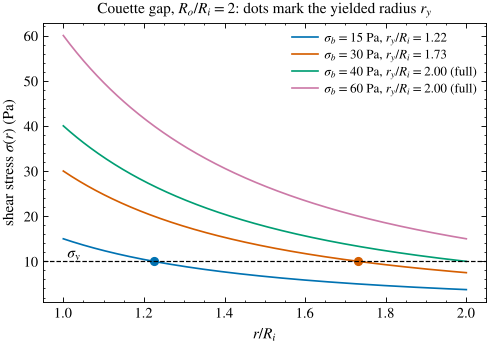

In [3]:
kappa = 2.0
Ro = kappa * Ri
r = np.linspace(Ri, Ro, 300)

fig, ax = plt.subplots(figsize=(5.2, 3.3))
for sb, col in zip([15, 30, 40, 60], [C["blue"], C["red"], C["green"], C["purple"]]):
    sig = sb * (Ri / r) ** 2                       # sigma(r) = sigma_b (Ri/r)^2
    ry = Ri * np.sqrt(sb / sigma_y)                # yielded radius
    ax.plot(r / Ri, sig, color=col, label=rf"$\sigma_b={sb}$ Pa, $r_y/R_i={min(ry, Ro):.2f}$" + (" (full)" if ry >= Ro else ""))
    if ry < Ro:
        ax.plot([ry / Ri], [sigma_y], "o", color=col, ms=5)
ax.axhline(sigma_y, color="k", lw=0.8, ls="--")
ax.text(1.01, sigma_y + 0.8, r"$\sigma_y$", fontsize=10)
ax.set_xlabel(r"$r/R_i$")
ax.set_ylabel(r"shear stress $\sigma(r)$ (Pa)")
ax.set_title(r"Couette gap, $R_o/R_i=2$: dots mark the yielded radius $r_y$", fontsize=10)
ax.legend(fontsize=8.5)
plt.show()

With $\kappa=2$ the stress falls by a factor $\kappa^2=4$ across the gap. A bob stress of 30 Pa (three times the yield stress) still leaves the outer part of the gap unyielded; the gap is fully sheared only for $\sigma_b\ge 4\sigma_y=40$ Pa.

## 4. Sheared fraction of the gap — Fig. 6(a)

In [4]:
def sheared_fraction(sb_over_sy, kappa):
    """(r_y - Ri)/(Ro - Ri), capped at 1 (fully sheared)."""
    ry_over_Ri = np.sqrt(np.asarray(sb_over_sy, float))
    return np.clip((ry_over_Ri - 1.0) / (kappa - 1.0), 0.0, 1.0)

for kappa in kappas:
    print(f"kappa = {kappa:5.3f}: gap fully sheared for sigma_b/sigma_y >= kappa^2 = {kappa**2:.3f}"
          f"  (sigma_b >= {sigma_y * kappa**2:.1f} Pa)")

kappa = 1.068: gap fully sheared for sigma_b/sigma_y >= kappa^2 = 1.141  (sigma_b >= 11.4 Pa)
kappa = 1.500: gap fully sheared for sigma_b/sigma_y >= kappa^2 = 2.250  (sigma_b >= 22.5 Pa)
kappa = 2.000: gap fully sheared for sigma_b/sigma_y >= kappa^2 = 4.000  (sigma_b >= 40.0 Pa)


For the narrow field-viscometer gap the bob stress need exceed the yield stress by only 14 %, but for $\kappa=2$ it must reach four times the yield stress. The plot is drawn after the torque–speed relation has been set up (Sec. 7, where both panels of Fig. 6 are reproduced).

## 5. The torque–speed relation, Eq. (21)

We implement Eq. (21) (integral over radius) and Eq. (S15) (integral over stress) independently and check that they agree.

In [5]:
def omega_radius(sb, kappa, ty=sigma_y, K=K, n=n):
    """Eq. (21): inner angular velocity (rad/s) for bob stress sb, outer cylinder at rest."""
    if sb <= ty:
        return 0.0
    Ro = kappa * Ri
    r_max = min(Ri * np.sqrt(sb / ty), Ro) if ty > 0 else Ro
    integrand = lambda rr: ((sb * (Ri / rr) ** 2 - ty) / K) ** (1 / n) / rr
    return quad(integrand, Ri, r_max, limit=200)[0]

def omega_stress(sb, kappa, ty=sigma_y, K=K, n=n):
    """Eq. (S15): the same quantity written as an integral over the local stress s."""
    if sb <= ty:
        return 0.0
    s_low = max(ty, sb / kappa**2)
    return quad(lambda s: (s - ty) ** (1 / n) / s, s_low, sb, limit=200)[0] / (2 * K ** (1 / n))

worst = 0.0
for kappa in kappas:
    for sb in [10.5, 12, 20, 45, 200]:
        a, b = omega_radius(sb, kappa), omega_stress(sb, kappa)
        worst = max(worst, abs(a / b - 1))
print(f"Eq. (21) vs Eq. (S15): largest relative difference = {worst:.1e}")
assert worst < 1e-8

Eq. (21) vs Eq. (S15): largest relative difference = 1.8e-14


### 5.1 Classical limits

Before trusting Eq. (21) for an HB fluid we check it against closed forms that follow from it when the integral can be done by hand (these are the checks listed in Supplementary Table SV and coded in `scripts/verify_equations.py`). In terms of the torque per unit length $T=2\pi R_i^2\sigma_b$:

* Newtonian ($\sigma_y=0$, $n=1$, $K=\mu$): $\Omega = \dfrac{T}{4\pi\mu}\left(\dfrac{1}{R_i^2}-\dfrac{1}{R_o^2}\right)$;
* power law ($\sigma_y=0$): $\Omega = \dfrac{n}{2}\left(\dfrac{T}{2\pi K}\right)^{1/n}\left(R_i^{-2/n}-R_o^{-2/n}\right)$;
* Bingham ($n=1$, $K=\mu_p$), with $r_m=\min(r_y,R_o)$: $\Omega = \dfrac{T}{4\pi\mu_p}\left(\dfrac{1}{R_i^2}-\dfrac{1}{r_m^2}\right)-\dfrac{\sigma_y}{\mu_p}\ln\dfrac{r_m}{R_i}$.

The Bingham form covers both the partially sheared ($r_m=r_y$) and the fully sheared ($r_m=R_o$) gap.

In [6]:
mu = 2.0          # Pa s, Newtonian viscosity / Bingham plastic viscosity for the checks
kappa = 1.5
Ro = kappa * Ri
for sb in [12.0, 30.0]:
    T = 2 * np.pi * Ri**2 * sb
    # Newtonian
    exact = T / (4 * np.pi * mu) * (1 / Ri**2 - 1 / Ro**2)
    assert np.isclose(omega_stress(sb, kappa, ty=0.0, K=mu, n=1.0), exact, rtol=1e-10)
    # power law
    for npl in [0.4, 0.8]:
        exact = npl / 2 * (T / (2 * np.pi * K)) ** (1 / npl) * (Ri ** (-2 / npl) - Ro ** (-2 / npl))
        assert np.isclose(omega_stress(sb, kappa, ty=0.0, K=K, n=npl), exact, rtol=1e-8)
    # Bingham, partially (sb=12) and fully (sb=30) sheared
    rm = min(np.sqrt(T / (2 * np.pi * sigma_y)), Ro)
    exact = T / (4 * np.pi * mu) * (1 / Ri**2 - 1 / rm**2) - sigma_y / mu * np.log(rm / Ri)
    assert np.isclose(omega_stress(sb, kappa, K=mu, n=1.0), exact, rtol=1e-8)
print("Eq. (21) reproduces the Newtonian, power-law and Bingham closed forms (partially and fully sheared).")

Eq. (21) reproduces the Newtonian, power-law and Bingham closed forms (partially and fully sheared).


### 5.2 Torque–speed curves and the near-onset exponent

Now the HB fluid itself. We plot $\Omega$ against the excess bob stress $\delta=\sigma_b-\sigma_y$ on logarithmic axes, together with the near-onset asymptote (S16). The local slope $\mathrm{d}\ln\Omega/\mathrm{d}\ln\delta$ starts at $1+1/n=3$ and only later approaches the "material" value $1/n=2$.

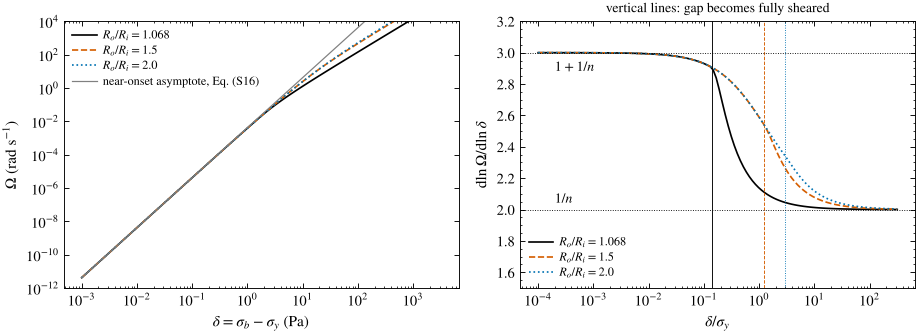

Omega / asymptote at delta = 1e-5 sigma_y: 0.999993


In [7]:
delta = np.logspace(-4, 2.5, 120) * sigma_y           # excess bob stress (Pa)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 3.3))
for kappa in kappas:
    col, ls, _ = styles[kappa]
    Om = np.array([omega_stress(sigma_y + d, kappa) for d in delta])
    ax1.loglog(delta, Om, color=col, ls=ls, label=rf"$R_o/R_i={kappa}$")
    slope = np.gradient(np.log(Om), np.log(delta))
    ax2.semilogx(delta / sigma_y, slope, color=col, ls=ls, label=rf"$R_o/R_i={kappa}$")
    ax2.axvline(kappa**2 - 1, color=col, lw=0.6, ls=ls)          # full shearing reached here
asym = n / (2 * (n + 1) * K ** (1 / n) * sigma_y) * delta ** (1 + 1 / n)
ax1.loglog(delta, asym, color=C["grey"], lw=0.8, label="near-onset asymptote, Eq. (S16)")
ax1.set_xlabel(r"$\delta=\sigma_b-\sigma_y$ (Pa)")
ax1.set_ylabel(r"$\Omega$ (rad s$^{-1}$)")
ax1.set_ylim(1e-12, 1e4)
ax1.legend(fontsize=8)
ax2.axhline(1 + 1 / n, color="k", lw=0.6, ls=":")
ax2.axhline(1 / n, color="k", lw=0.6, ls=":")
ax2.text(2e-4, 1 + 1 / n - 0.12, r"$1+1/n$", fontsize=9)
ax2.text(2e-4, 1 / n + 0.04, r"$1/n$", fontsize=9)
ax2.set_xlabel(r"$\delta/\sigma_y$")
ax2.set_ylabel(r"$\mathrm{d}\ln\Omega/\mathrm{d}\ln\delta$")
ax2.set_ylim(1.5, 3.2)
ax2.legend(fontsize=8, loc="lower left")
ax2.set_title("vertical lines: gap becomes fully sheared", fontsize=9)
fig.tight_layout()
plt.show()

# Check the asymptote (S16) close to onset
d_small = 1e-5 * sigma_y
ratio = omega_stress(sigma_y + d_small, 2.0) / (n / (2 * (n + 1) * K ** (1 / n) * sigma_y) * d_small ** (1 + 1 / n))
print(f"Omega / asymptote at delta = 1e-5 sigma_y: {ratio:.6f}")
assert abs(ratio - 1) < 1e-4

Once the gap is fully sheared (vertical lines) the slope falls quickly; far above yield it tends to $1/n$, but only slowly because the yield stress still contributes. A power law fitted to $\Omega$ versus excess torque near onset would therefore return an exponent that describes the geometry, not the material (Supplementary Note S7 A).

## 6. The Newtonian conversion and its bias

We now play the role of the rheometer software. For each bob stress we compute the exact $\Omega$, convert it with the Newtonian factor, and compare $\dot\gamma_{\rm app}$ with the true shear rate at the bob, $\dot\gamma_b = [(\sigma_b-\sigma_y)/K]^{1/n}$.

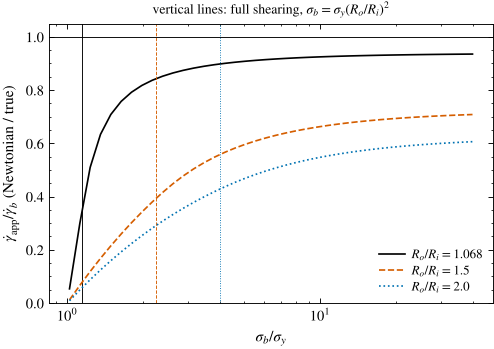

In [8]:
def newtonian_rate(Om, kappa):
    """Newtonian bob shear rate 2*Omega*Ro^2/(Ro^2 - Ri^2)."""
    return 2 * Om / (1 - kappa ** -2.0)

sb_grid = sigma_y * np.logspace(np.log10(1.02), np.log10(40), 40)     # same grid as Fig. 6(b)
fig, ax = plt.subplots(figsize=(5.2, 3.3))
for kappa in kappas:
    col, ls, _ = styles[kappa]
    Om = np.array([omega_stress(s, kappa) for s in sb_grid])
    ax.semilogx(sb_grid / sigma_y, newtonian_rate(Om, kappa) / hb_rate(sb_grid), color=col, ls=ls,
                label=rf"$R_o/R_i={kappa}$")
    ax.axvline(kappa**2, color=col, lw=0.6, ls=ls)
ax.axhline(1, color="k", lw=0.6)
ax.set_xlabel(r"$\sigma_b/\sigma_y$")
ax.set_ylabel(r"$\dot\gamma_{\rm app}/\dot\gamma_b$ (Newtonian / true)")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right", fontsize=8.5)
ax.set_title("vertical lines: full shearing, $\\sigma_b=\\sigma_y(R_o/R_i)^2$", fontsize=9)
plt.show()

The ratio is always below one: the Newtonian factor **underestimates** the bob shear rate, as Skadsem and Saasen (2019) showed. Close to the bob threshold the underestimate is enormous (the apparent rate is only a few per cent of the true one) because the whole deformation is concentrated in a thin layer. For $\kappa=1.068$ the underestimate is still about 25–30 % at $\sigma_b\approx1.5\,\sigma_y$, just above full shearing, falls to about 9 % at $5\,\sigma_y$ and levels off near 6 % far above yield (the residual error of a Newtonian factor applied to a shear-thinning fluid, which is small only because the gap is narrow). For $\kappa=2$ it remains about 40 % even at $\sigma_b=40\,\sigma_y$.

*Going beyond the review (pedagogical aside).* A classical improvement replaces the Newtonian factor by the power-law one, using the local slope $n_{\rm loc}=\mathrm{d}\ln\sigma_b/\mathrm{d}\ln\Omega$: $\dot\gamma_b\approx 2\Omega/[n_{\rm loc}(1-\kappa^{-2/n_{\rm loc}})]$. Such differential corrections belong to the family of classical inversions (Rabinowitsch, 1929; Mooney, 1931; Krieger and Maron, 1952) mentioned in Sec. VI B, which "require differentiation of noisy data or iteration". The next cell shows that, applied to exact data, it removes most of the bias except very close to the onset.

In [9]:
kappa = 2.0
Om = np.array([omega_stress(s, kappa) for s in sb_grid])
n_loc = np.gradient(np.log(sb_grid), np.log(Om))                  # local slope d ln(sigma_b)/d ln(Omega)
rate_pl = 2 * Om / (n_loc * (1 - kappa ** (-2 / n_loc)))         # power-law bob shear rate
for i in [0, 8, 16, 24, 39]:
    print(f"sigma_b/sigma_y = {sb_grid[i]/sigma_y:6.2f}:  Newtonian/true = {newtonian_rate(Om[i], kappa)/hb_rate(sb_grid[i]):.3f}"
          f"   local power-law/true = {rate_pl[i]/hb_rate(sb_grid[i]):.3f}")

sigma_b/sigma_y =   1.02:  Newtonian/true = 0.009   local power-law/true = 0.371
sigma_b/sigma_y =   2.17:  Newtonian/true = 0.281   local power-law/true = 1.001
sigma_b/sigma_y =   4.60:  Newtonian/true = 0.453   local power-law/true = 1.016
sigma_b/sigma_y =   9.75:  Newtonian/true = 0.546   local power-law/true = 1.011
sigma_b/sigma_y =  40.00:  Newtonian/true = 0.606   local power-law/true = 1.004


### 6.1 Apparent flow curves and fitted parameters — Fig. 6(b)

Following `scripts/fig06_couette_inverse.py`, we compute 40 torque–speed points per geometry ($1.02\le\sigma_b/\sigma_y\le40$, logarithmically spaced), convert them with the Newtonian factor, and fit the HB law to the apparent pairs $(\dot\gamma_{\rm app},\sigma_b)$ by unweighted least squares on $\ln\sigma$ (the objective recorded in `data/couette_illustration.json`).

In [10]:
def omega_fig6(tau_b, kappa):
    """Eq. (21) exactly as coded in scripts/fig06_couette_inverse.py (radius integral)."""
    return omega_radius(tau_b, kappa)

hb_model = lambda g, a, b, c: a + b * g**c          # sigma = sigma_y + K * gdot^n

apparent, fits = {}, {}
for kappa in kappas:
    Ro = kappa * Ri
    tbs = np.logspace(np.log10(sigma_y * 1.02), np.log10(sigma_y * 40), 40)
    Om = np.array([omega_fig6(t, kappa) for t in tbs])
    g_app = 2 * Om * Ro**2 / (Ro**2 - Ri**2)
    ok = g_app > 0
    p, _ = curve_fit(lambda g, a, b, c: np.log(hb_model(g, a, b, c)), g_app[ok], np.log(tbs[ok]),
                     p0=[8, 2, 0.5], bounds=([0, 1e-6, 0.05], [50, 100, 2]))
    apparent[kappa] = (g_app[ok], tbs[ok])
    fits[kappa] = p

print(f"true parameters:           sigma_y = {sigma_y:6.3f} Pa   K = {K:6.3f} Pa s^n   n = {n:5.3f}")
for kappa, (a, b, c) in fits.items():
    print(f"Newtonian conversion {kappa:5.3f}: sigma_y = {a:6.3f} Pa   K = {b:6.3f} Pa s^n   n = {c:5.3f}"
          f"   (bias {100*(a/sigma_y-1):+5.1f} %, {100*(b/K-1):+5.1f} %, {100*(c/n-1):+5.1f} %)")

true parameters:           sigma_y = 10.000 Pa   K =  2.000 Pa s^n   n = 0.500
Newtonian conversion 1.068: sigma_y = 10.445 Pa   K =  2.114 Pa s^n   n = 0.497   (bias  +4.5 %,  +5.7 %,  -0.5 %)
Newtonian conversion 1.500: sigma_y = 11.080 Pa   K =  2.946 Pa s^n   n = 0.476   (bias +10.8 %, +47.3 %,  -4.8 %)
Newtonian conversion 2.000: sigma_y = 11.047 Pa   K =  3.480 Pa s^n   n = 0.466   (bias +10.5 %, +74.0 %,  -6.8 %)


In [11]:
# Compare with the coefficients stored by the figure script
stored_fits = json.loads((ROOT / "data" / "couette_illustration.json").read_text())
assert stored_fits["true_triplet"] == [sigma_y, K, n]
for rec in stored_fits["fits"]:
    mine = fits[rec["radius_ratio"]]
    ref = [rec["tau_y_Pa"], rec["K_Pa_s_to_n"], rec["n"]]
    assert np.allclose(mine, ref, rtol=1e-6), (mine, ref)
print("Fitted triplets agree with data/couette_illustration.json to better than 1e-6 (relative).")

Fitted triplets agree with data/couette_illustration.json to better than 1e-6 (relative).


Every fit returns a yield stress that is too high (by 4–11 %), a consistency that is too high (by 6–74 %) and a flow index that is too low. The bias grows with the gap width. None of these fits looks bad on a log–log plot (next section) — nothing in the converted data warns the analyst.

## 7. Reproducing Fig. 6 and checking it against the stored figure data

We redraw both panels with the arrays used by the figure script and compare them with `data/figure_data/fig06_couette_inverse.csv`. Panel (b) here also shows, as thin lines, the HB fits of Sec. 6.1, which the published Fig. 6(b) does not draw. The CSV stores ten significant digits, so we require agreement to a relative tolerance of $10^{-8}$.

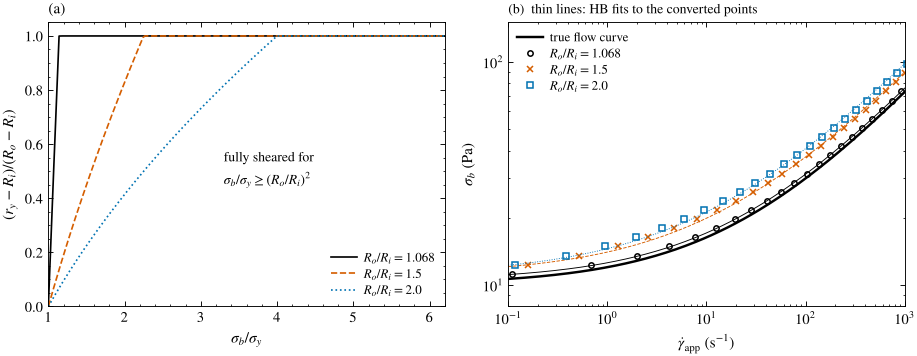

Fig. 6(a) and 6(b): all plotted values agree with data/figure_data/fig06_couette_inverse.csv (rtol 1e-8).


In [12]:
fd = pd.read_csv(ROOT / "data" / "figure_data" / "fig06_couette_inverse.csv", comment="#")
def stored(panel, series):
    s = fd[(fd.panel == panel) & (fd.series == series)].sort_values("index")
    return s.x.to_numpy(), s.y.to_numpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 3.5))
# (a) sheared fraction versus bob stress
tb = np.linspace(sigma_y * 1.0001, 80, 300)
for kappa in kappas:
    col, ls, mk = styles[kappa]
    frac = sheared_fraction(tb / sigma_y, kappa)
    ax1.plot(tb / sigma_y, frac, color=col, ls=ls, label=rf"$R_o/R_i={kappa}$")
    xs, ys = stored("(a)", f"$R_o/R_i={kappa}$")
    assert np.allclose(xs, tb / sigma_y, rtol=1e-8) and np.allclose(ys, frac, rtol=1e-8, atol=1e-12)
ax1.set_xlabel(r"$\sigma_b/\sigma_y$"); ax1.set_ylabel(r"$(r_y-R_i)/(R_o-R_i)$")
ax1.set_xlim(1, 6.2); ax1.set_ylim(0, 1.05)
ax1.legend(loc="lower right", fontsize=8.5)
ax1.text(3.3, 0.45, "fully sheared for\n" + r"$\sigma_b/\sigma_y\geq(R_o/R_i)^2$", fontsize=9)
ax1.set_title("(a)", loc="left", fontsize=10)

# (b) apparent flow curves from the Newtonian conversion
gfine = np.logspace(-1, 3, 200)
ax2.loglog(gfine, sigma_y + K * gfine**n, color="k", lw=1.6, label="true flow curve")
xs, ys = stored("(b)", "true flow curve")
assert np.allclose(xs, gfine, rtol=1e-8) and np.allclose(ys, sigma_y + K * gfine**n, rtol=1e-8)
for kappa in kappas:
    col, ls, mk = styles[kappa]
    g_app, tbs = apparent[kappa]
    ax2.loglog(g_app, tbs, mk, ms=3.5, color=col, mfc="none" if mk != "x" else col, label=rf"$R_o/R_i={kappa}$")
    ax2.loglog(gfine, hb_model(gfine, *fits[kappa]), color=col, lw=0.6, ls=ls)
    xs, ys = stored("(b)", f"$R_o/R_i={kappa}$")
    assert np.allclose(xs, g_app, rtol=1e-8) and np.allclose(ys, tbs, rtol=1e-8)
ax2.set_xlabel(r"$\dot\gamma_{\rm app}$ (s$^{-1}$)"); ax2.set_ylabel(r"$\sigma_b$ (Pa)")
ax2.set_xlim(1e-1, 1e3); ax2.set_ylim(8, 150)
ax2.legend(loc="upper left", fontsize=8.5)
ax2.set_title("(b)  thin lines: HB fits to the converted points", loc="left", fontsize=9)
fig.tight_layout()
plt.show()
print("Fig. 6(a) and 6(b): all plotted values agree with data/figure_data/fig06_couette_inverse.csv (rtol 1e-8).")

In panel (b) the converted points lie to the **left** of the true curve (too low a shear rate for a given stress); the wider the gap, the further they lie from the truth. Near the onset the points pile up along a nearly vertical line at $\sigma_b\approx\sigma_y$, at apparent rates down to $10^{-4}$ s$^{-1}$, outside the plotted window.

## 8. The remedy: fit the raw observables through the forward model

Sec. VI B recommends fitting "the raw observables through the forward instrument model, which avoids treating a processed stress–rate pair as error-free on one axis". *Going beyond the review*, we illustrate this with synthetic torque–speed data for the widest gap ($\kappa=2$), with 2 % multiplicative noise on $\Omega$ (fixed random seed). We fit $(\sigma_y, K, n)$ by least squares on $\ln\Omega$, computing each model value from Eq. (S15), and compare with an HB fit of the same noisy data after the Newtonian conversion.

In [13]:
rng = np.random.default_rng(20261028)               # fixed seed: deterministic notebook
kappa = 2.0
tbs = np.logspace(np.log10(sigma_y * 1.02), np.log10(sigma_y * 40), 40)
Om_true = np.array([omega_stress(t, kappa) for t in tbs])
Om_meas = Om_true * np.exp(0.02 * rng.standard_normal(tbs.size))     # 2 % noise on the speed

# (i) forward-model fit: predict Omega from Eq. (S15) for trial parameters
def resid_forward(p):
    ty, k, m = p
    model = np.array([omega_stress(t, kappa, ty=ty, K=k, n=m) for t in tbs])
    return np.log(model) - np.log(Om_meas)
fwd = least_squares(resid_forward, x0=[8.0, 1.5, 0.6],
                    bounds=([0.0, 1e-3, 0.1], [0.999 * tbs.min(), 50.0, 2.0]))

# (ii) conventional route: Newtonian conversion, then an HB fit in log stress
g_app = newtonian_rate(Om_meas, kappa)
conv, _ = curve_fit(lambda g, a, b, c: np.log(hb_model(g, a, b, c)), g_app, np.log(tbs),
                    p0=[8, 2, 0.5], bounds=([0, 1e-6, 0.05], [50, 100, 2]))

print(f"true:                    sigma_y = {sigma_y:6.3f} Pa  K = {K:6.3f}  n = {n:5.3f}")
print(f"forward model, Eq.(S15): sigma_y = {fwd.x[0]:6.3f} Pa  K = {fwd.x[1]:6.3f}  n = {fwd.x[2]:5.3f}")
print(f"Newtonian conversion:    sigma_y = {conv[0]:6.3f} Pa  K = {conv[1]:6.3f}  n = {conv[2]:5.3f}")

true:                    sigma_y = 10.000 Pa  K =  2.000  n = 0.500
forward model, Eq.(S15): sigma_y = 10.001 Pa  K =  1.997  n = 0.500
Newtonian conversion:    sigma_y = 11.062 Pa  K =  3.459  n = 0.466


The forward-model fit recovers the true triplet to within the noise, while the converted data return the same biased parameters as in Sec. 6.1, whatever the noise. The bias of the conversion is systematic, so taking more data does not remove it. (The parameter intervals from such fits should come from profile likelihood or bootstrap, Sec. VI D; that is the subject of another notebook.)

## 9. Practical advice on the gap ratio

The table below collects, for several radius ratios, the stress drop across the gap, the bob stress needed to shear the whole gap, and the error of the Newtonian bob shear rate ($\dot\gamma_{\rm app}/\dot\gamma_b-1$) at two bob stresses for the Fig. 6 material.

In [14]:
rows = []
for kappa in [1.02, 1.068, 1.1, 1.2, 1.5, 2.0]:
    row = {"Ro/Ri": f"{kappa:g}",
           "stress drop across gap (%)": round(100 * (1 - kappa**-2), 1),
           "full shearing for sigma_b/sigma_y >=": round(kappa**2, 3)}
    for ratio in [1.5, 5.0]:
        sb = ratio * sigma_y
        err = 100 * (newtonian_rate(omega_stress(sb, kappa), kappa) / hb_rate(sb) - 1)
        row[f"rate error at {ratio:g} sigma_y (%)"] = round(err, 1)
    rows.append(row)
pd.DataFrame(rows).set_index("Ro/Ri")

,stress drop across gap (%),full shearing for sigma_b/sigma_y >=,rate error at 1.5 sigma_y (%),rate error at 5 sigma_y (%)
Ro/Ri,,,,
1.02,3.9,1.040,-9.5,-2.9
1.068,12.3,1.141,-28.6,-9.2
1.1,17.4,1.210,-38.8,-12.9
1.2,30.6,1.440,-60.1,-22.7
1.5,55.6,2.250,-78.1,-40.5
2,75.0,4.000,-83.8,-53.3


What the review recommends, and what the numbers show:

* **Check the full-shearing condition for every point.** A point with $\sigma_b<\sigma_y(R_o/R_i)^2$ comes from a partially sheared gap and must not be converted with Newtonian (or any homogeneous-shear) factors (Secs. VI B, VII A).
* **Prefer a narrow gap if you must use a conversion formula.** For the near-unity ratio of the standard field geometry ($\kappa=1.068$) the error is small and the gap is fully sheared once $\sigma_b$ exceeds $\sigma_y$ by 14 %; wider gaps require correction (Skadsem and Saasen, 2019; Sec. VI B).
* **Better still, fit the raw torque and speed through Eq. (21).** This is the forward model the review recommends (Secs. VI B and VII A); it is exact for any gap, partially or fully sheared, provided its assumptions — no slip, no end effects, steady and homogeneous material — hold.
* **But do not make the gap too narrow for the material.** The gap must be large compared with the particle, droplet or bubble size, and slip must be suppressed (roughened or serrated walls, or a vane; Barnes and Nguyen, 2001) and checked with two gaps or velocimetry. Parameters measured in gaps that are not large compared with the structural scale (Goyon et al., 2008), or without a slip check, are apparent parameters (Sec. VI C).

## 10. Try it yourself

**Exercise 1 — the field viscometer.** For the Fig. 6 material ($\sigma_y=10$ Pa) in the $\kappa=1.068$ geometry: (a) what bob stress fully shears the gap? (b) What fraction of the gap is sheared at $\sigma_b=1.05\,\sigma_y$, and by how much does the Newtonian factor underestimate the bob shear rate there?

*Hint:* use `sheared_fraction`, `omega_stress`, `newtonian_rate` and `hb_rate`.

<details><summary>Solution</summary>

```python
kappa = 1.068
print("full shearing at sigma_b =", sigma_y * kappa**2, "Pa")          # 11.41 Pa
sb = 1.05 * sigma_y
print("sheared fraction:", sheared_fraction(sb / sigma_y, kappa))       # about 0.36
print("Newtonian/true rate:", newtonian_rate(omega_stress(sb, kappa), kappa) / hb_rate(sb))   # about 0.13: the rate is underestimated almost eightfold
```
</details>

**Exercise 2 — a Bingham fluid.** Repeat the Fig. 6(b) fit (Sec. 6.1) for a Bingham fluid ($n=1$, $K=2$ Pa s, $\sigma_y=10$ Pa) with $\kappa=1.5$, fitting the full three-parameter HB law. In which direction are $\sigma_y$, $K$ and $n$ biased?

*Hint:* pass `K=2.0, n=1.0` to `omega_stress` and keep the rest of the cell unchanged.

<details><summary>Solution</summary>

```python
kappa, Ro = 1.5, 1.5 * Ri
tbs = np.logspace(np.log10(sigma_y * 1.02), np.log10(sigma_y * 40), 40)
Om = np.array([omega_stress(t, kappa, K=2.0, n=1.0) for t in tbs])
g_app = 2 * Om * Ro**2 / (Ro**2 - Ri**2)
p, _ = curve_fit(lambda g, a, b, c: np.log(hb_model(g, a, b, c)), g_app, np.log(tbs),
                 p0=[8, 2, 0.8], bounds=([0, 1e-6, 0.05], [50, 100, 2]))
print(p)   # yield stress and consistency too high, flow index below 1: a Bingham fluid looks shear-thinning
```
</details>

**Exercise 3 — size does not matter, the ratio does.** Show numerically that, at fixed $\sigma_b$ and $\kappa$, $\Omega$ is the same for a bob of radius 1 cm and 1 m, whereas at fixed *torque per unit length* it is not.

*Hint:* `omega_radius` uses the global `Ri`; write a version that takes `Ri` as an argument.

<details><summary>Solution</summary>

```python
def omega_Ri(sb, kappa, Ri):
    if sb <= sigma_y:
        return 0.0                                              # below the bob threshold: no flow
    rmax = min(Ri * np.sqrt(sb / sigma_y), kappa * Ri)
    return quad(lambda rr: ((sb * (Ri / rr)**2 - sigma_y) / K)**(1 / n) / rr, Ri, rmax)[0]
print(omega_Ri(25, 1.5, 0.01), omega_Ri(25, 1.5, 1.0))       # identical
T = 2 * np.pi * 0.01**2 * 25                                   # torque per length for the small bob
print(omega_Ri(T / (2 * np.pi * 1.0**2), 1.5, 1.0))            # large bob, same T: below yield, Omega = 0
```
</details>

## Key points

* In a Couette cell the shear stress decays as $\sigma_b(R_i/r)^2$; the material yields only inside $r_y=R_i\sqrt{\sigma_b/\sigma_y}$.
* The gap is fully sheared only for $\sigma_b\ge\sigma_y(R_o/R_i)^2$ — 1.14 $\sigma_y$ for $\kappa=1.068$, but 4 $\sigma_y$ for $\kappa=2$.
* Eq. (21) is the exact no-slip torque–speed relation; near onset $\Omega\propto(\sigma_b-\sigma_y)^{1+1/n}$ because the sheared layer is thin.
* Converting partially sheared data with Newtonian factors underestimates the shear rate and biases all three fitted parameters ($\sigma_y$ and $K$ high, $n$ low here), increasingly so for wider gaps.
* Use a narrow gap, check the full-shearing condition, and preferably fit raw torque and speed through Eq. (21); keep the gap large compared with the microstructure and control slip.

## References

The review and its repository:
* Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

* Herschel, W. H., and Bulkley, R. (1926). Konsistenzmessungen von Gummi-Benzollösungen. *Kolloid-Zeitschrift* **39**, 291–300. https://doi.org/10.1007/bf01432034
* Reiner, M., and Riwlin, R. (1927). Die Theorie der Strömung einer elastischen Flüssigkeit im Couette-Apparat. *Kolloid-Zeitschrift* **43**, 1–5. https://doi.org/10.1007/bf01451550
* Rabinowitsch, B. (1929). Über die Viskosität und Elastizität von Solen. *Zeitschrift für Physikalische Chemie* **145A**, 1–26. https://doi.org/10.1515/zpch-1929-14502
* Mooney, M. (1931). Explicit formulas for slip and fluidity. *Journal of Rheology* **2**, 210–222. https://doi.org/10.1122/1.2116364
* Krieger, I. M., and Maron, S. H. (1952). Direct determination of the flow curves of non-Newtonian fluids. *Journal of Applied Physics* **23**, 147–149. https://doi.org/10.1063/1.1701961
* Barnes, H. A., and Nguyen, Q. D. (2001). Rotating vane rheometry — a review. *Journal of Non-Newtonian Fluid Mechanics* **98**, 1–14. https://doi.org/10.1016/S0377-0257(01)00095-7
* Goyon, J., Colin, A., Ovarlez, G., Ajdari, A., and Bocquet, L. (2008). Spatial cooperativity in soft glassy flows. *Nature* **454**, 84–87. https://doi.org/10.1038/nature07026
* Skadsem, H. J., and Saasen, A. (2019). Concentric cylinder viscometer flows of Herschel–Bulkley fluids. *Applied Rheology* **29**, 173–181. https://doi.org/10.1515/arh-2019-0015